**Project TEAMID** - PTID-CDS-JUL-26-11218

**Project CODE** - PRCP-1001-RiceLeafDisease

**Project Name** - Rice Leaf Disease Detection

**Project Type** - Deep Learning / Computer Vision

**Contribution** - Individual

## Problem Statement

Task 1:-Prepare a complete data analysis report on the given data.

Task 2:-Create a model which can classify the three major attacking diseases of rice plants like leaf blast, bacterial blight and brown spot.

Task3:- Analyze various techniques like Data Augmentation, etc and create a report on that.



### Business Objective

- To develop a deep learning model for rice leaf disease detection.
- To identify diseases from rice leaf images automatically.
- To classify leaves into Bacterial Leaf Blight, Brown Spot, and Leaf Smut.
- To help farmers detect diseases at an early stage.
- To reduce crop losses through timely disease identification.
- To improve rice crop health and productivity.

## 1. Import Libraries

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report, confusion_matrix

print("Tensorflow version: ", tf.version)

Tensorflow version:  <module 'tensorflow._api.v2.version' from 'C:\\Users\\ALPNA\\anaconda3\\envs\\riceleaf\\Lib\\site-packages\\tensorflow\\_api\\v2\\version\\__init__.py'>


## 2. Load Dataset

In [2]:
DATA_DIR = r"Data"

IMG_SIZE = (128, 128)
BATCH_SIZE = 32
SEED = 42

print("Dataset path: ", DATA_DIR)


Dataset path:  Data


## 3. Data Analysis

#### Check the classes and number of images

In [3]:
classes = sorted([
    folder for folder in os.listdir(DATA_DIR)
    if os.path.isdir(os.path.join(DATA_DIR, folder))
])

print("Classes:", classes)

for class_name in classes:
    folder = os.path.join(DATA_DIR, class_name)
    image_count = len([
        file for file in os.listdir(folder)
        if file.lower().endswith((".jpg", ".jpeg", ".png"))
    ])
    print(f"{class_name}: {image_count} images")

Classes: ['Bacterial leaf blight', 'Brown spot', 'Leaf smut']
Bacterial leaf blight: 40 images
Brown spot: 40 images
Leaf smut: 39 images


In [4]:
# Create a simple class-count table
data = []

for class_name in classes:
    folder = os.path.join(DATA_DIR, class_name)
    files = [
        file for file in os.listdir(folder)
        if file.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    for file in files:
        data.append([class_name, os.path.join(folder, file)])

df = pd.DataFrame(data, columns=["Class", "File"])

print(df.head())
print("\nTotal images:", len(df))
print("\nImages per class:")
print(df["Class"].value_counts())


                   Class                                     File
0  Bacterial leaf blight  Data\Bacterial leaf blight\DSC_0365.JPG
1  Bacterial leaf blight  Data\Bacterial leaf blight\DSC_0366.jpg
2  Bacterial leaf blight  Data\Bacterial leaf blight\DSC_0367.JPG
3  Bacterial leaf blight  Data\Bacterial leaf blight\DSC_0370.jpg
4  Bacterial leaf blight  Data\Bacterial leaf blight\DSC_0372.JPG

Total images: 119

Images per class:
Class
Bacterial leaf blight    40
Brown spot               40
Leaf smut                39
Name: count, dtype: int64


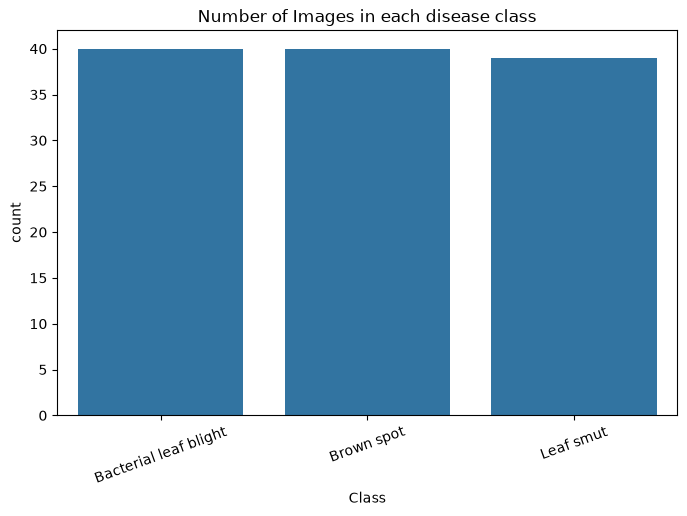

In [5]:
# Visualize the class distribution

plt.figure(figsize=(8, 5))
sns.countplot(data = df, x ="Class")
plt.title("Number of Images in each disease class")
plt.xticks(rotation = 20)
plt.show()

#### Display smaple images

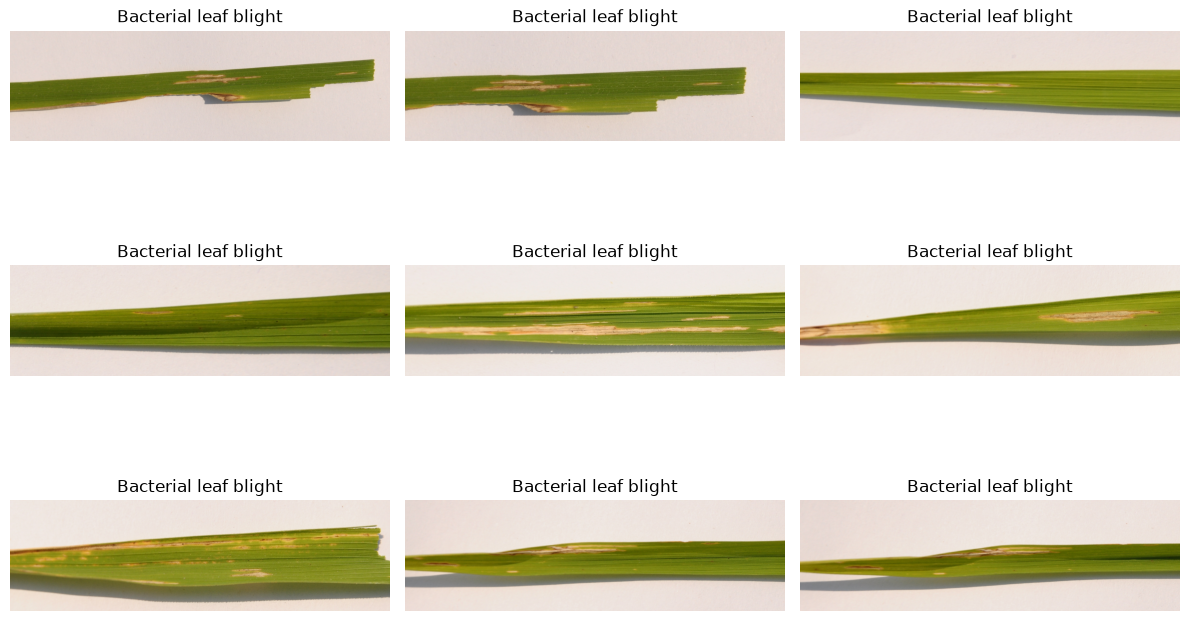

In [6]:
plt.figure(figsize=(12, 8))

for i in range(min(9, len(df))):
    image = plt.imread(df.iloc[i]["File"])

    plt.subplot(3, 3, i + 1)
    plt.imshow(image)
    plt.title(df.iloc[i]["Class"])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [7]:
## Check image size

sizes = []

for file in df["File"]:
    image = tf.keras.utils.load_img(file)
    sizes.append(image.size)

size_df = pd.DataFrame(sizes, columns=["Width", "Height"])

print(size_df.describe())

             Width      Height
count   119.000000  119.000000
mean   2383.638655  707.739496
std    1123.528972  311.657582
min     250.000000   71.000000
25%    1074.000000  377.000000
50%    3081.000000  897.000000
75%    3081.000000  897.000000
max    3081.000000  900.000000


### 📊 Data Analysis Report

The dataset contains **119 rice leaf images** belonging to three disease classes:

- **Bacterial leaf blight:** 40 images
- **Brown spot:** 40 images
- **Leaf smut:** 39 images

The dataset is **well balanced**, as all three classes have nearly the same number of images. This is beneficial for training a classification model because there is no major class imbalance.

The image dimensions vary considerably. The width ranges from **250 to 3081 pixels**, while the height ranges from **71 to 900 pixels**. Therefore, image preprocessing is required before training the CNN.

For the model, all images will be resized to **128 × 128 pixels** to provide a consistent input size.

#### Key Findings
- Total images: **119**
- Number of classes: **3**
- Dataset is nearly balanced.
- Image resolutions vary significantly.
- Images will be resized to **128 × 128**.
- Data augmentation can help improve model generalization and reduce overfitting.

## 4. Creating Training, Validation and Test sets

We use:
- **70% training** → model learns patterns
- **15% validation** → monitor learning during training
- **15% testing** → final evaluation

The split is done automatically using `image_dataset_from_directory`.


In [8]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split = 0.30,
    subset = "training",
    seed = SEED,
    image_size = IMG_SIZE,
    batch_size = BATCH_SIZE 
)

temp_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split = 0.30,
    subset = "validation",
    seed =  SEED,
    image_size = IMG_SIZE,
    batch_size = BATCH_SIZE
)

class_names = train_ds.class_names

temp_batches = tf.data.experimental.cardinality(temp_ds).numpy()
test_batches = max(1, temp_batches // 2)

test_ds = temp_ds.take(test_batches)
val_ds = temp_ds.take(test_batches)

print("Classes: ", class_names)


Found 120 files belonging to 3 classes.
Using 84 files for training.
Found 120 files belonging to 3 classes.
Using 36 files for validation.
Classes:  ['Bacterial leaf blight', 'Brown spot', 'Leaf smut']


In [9]:
## Improve input pipeline speed

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().shuffle(100).prefetch(buffer_size = AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size = AUTOTUNE)
test_ds = test_ds.cache().prefetch(buffer_size = AUTOTUNE)

## 5. Build a Simple CNN

CNN means **Convolutional Neural Network**.

CNN has:
1. `Rescaling` → changes pixel values from 0–255 to 0–1
2. `Conv2D` → finds useful image patterns
3. `MaxPooling2D` → reduces image size
4. `Flatten` → converts feature maps into a vector
5. `Dense` → performs classification
6. `Dropout` → helps reduce overfitting


In [10]:
cnn = models.Sequential([
    layers.Rescaling(1./255, input_shape=(128, 128, 3)),

    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(3, activation="softmax")
])

cnn.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn.summary()


C:\Users\ALPNA\anaconda3\envs\riceleaf\Lib\site-packages\keras\src\layers\preprocessing\data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)                │ (None, 128, 128, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 126, 126, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 63, 63, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 61, 61, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 30, 30, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 28, 28, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 14, 14, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 25088)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │       3,211,392 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 3)                   │             387 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,305,027 (12.61 MB)

 Trainable params: 3,305,027 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

## 6. Train the CNN

In [11]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor = "val_loss",
    patience = 5,
    restore_best_weights = True
)

history = cnn.fit(
    train_ds,
    validation_data = val_ds,
    epochs = 50,
    callbacks = [early_stop]
)

Epoch 1/50


C:\Users\ALPNA\anaconda3\envs\riceleaf\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 649ms/step - accuracy: 0.3214 - loss: 1.3723 - val_accuracy: 0.3438 - val_loss: 1.0968
Epoch 2/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 434ms/step - accuracy: 0.4167 - loss: 1.0968 - val_accuracy: 0.3750 - val_loss: 1.0892
Epoch 3/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 431ms/step - accuracy: 0.4524 - loss: 1.0650 - val_accuracy: 0.3750 - val_loss: 1.0872
Epoch 4/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 488ms/step - accuracy: 0.4048 - loss: 1.0687 - val_accuracy: 0.4062 - val_loss: 1.0969
Epoch 5/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 429ms/step - accuracy: 0.5000 - loss: 0.9994 - val_accuracy: 0.4688 - val_loss: 1.0511
Epoch 6/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 460ms/step - accuracy: 0.6071 - loss: 0.9407 - val_accuracy: 0.4688 - val_loss: 0.9862
Epoch 7/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 457ms/step - accuracy: 0.6310 - loss: 0.8378 - val_accuracy: 0.4375 - val_loss: 1.0091
Epoch 8/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 427ms/step - accuracy: 0.5714 - loss: 0.8430 - val_accuracy: 0.5000 - val_loss: 0.9051
Epo

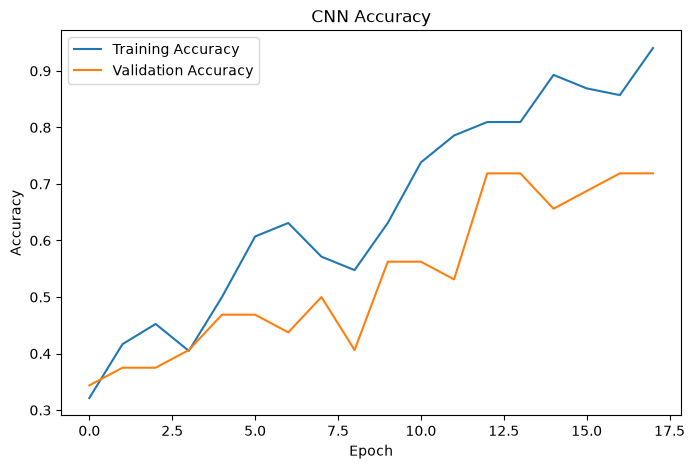

In [12]:
## Plot training and validation accuracy

plt.figure(figsize = (8,5))
plt.plot(history.history["accuracy"], label = "Training Accuracy")
plt.plot(history.history["val_accuracy"], label = "Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Accuracy")
plt.legend()
plt.show()

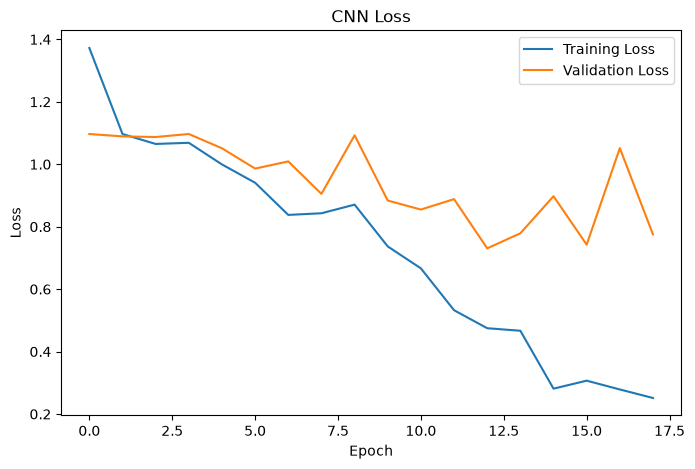

In [13]:
## Plot training and validation loss

plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Loss")
plt.legend()
plt.show()


## 7. Evaluate the CNN

We use:
- Accuracy
- Precision
- Recall
- F1-score
- Confusion matrix

These metrics help us understand more than just the overall accuracy.


In [14]:
test_loss, test_accuracy = cnn.evaluate(test_ds)

print("Test Loss: ", test_loss)
print("Test Accuracy: ", test_accuracy)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 234ms/step - accuracy: 0.6875 - loss: 0.7688
Test Loss:  0.7687599658966064
Test Accuracy:  0.6875


In [15]:
y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = cnn.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    zero_division=0
))


                       precision    recall  f1-score   support

Bacterial leaf blight       0.67      0.86      0.75         7
           Brown spot       0.70      0.64      0.67        11
            Leaf smut       0.69      0.64      0.67        14

             accuracy                           0.69        32
            macro avg       0.69      0.71      0.69        32
         weighted avg       0.69      0.69      0.68        32



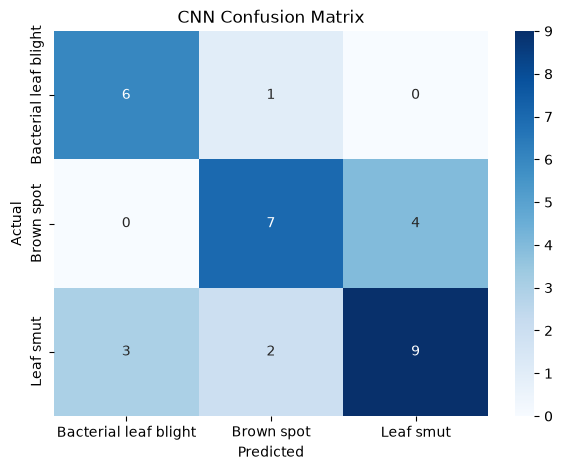

In [16]:
# Confusion matrix

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names,
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("CNN Confusion Matrix")
plt.show()


## 8. Data Augmentation

In [17]:
data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
], name="data_augmentation")

In [18]:
test_image = tf.random.uniform((1, 128, 128, 3))

augmented_image = data_augmentation(test_image)

print("Input shape:", test_image.shape)
print("Output shape:", augmented_image.shape)

Input shape: (1, 128, 128, 3)
Output shape: (1, 128, 128, 3)


## 9. CNN + Data Augmentation

Now we train the same basic CNN architecture, but augmentation is applied before the convolution layers.

This gives us a fair experiment:

**Model 1:** CNN without augmentation  
**Model 2:** CNN with augmentation


In [19]:
# CNN with Data Augmentation

cnn_aug = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    data_augmentation,

    layers.Rescaling(1./255),

    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(3, activation="softmax")
])

cnn_aug.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_aug.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)       │ (None, 128, 128, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rescaling_1 (Rescaling)              │ (None, 128, 128, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 126, 126, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 63, 63, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 61, 61, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 30, 30, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 28, 28, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (None, 14, 14, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 25088)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │       3,211,392 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 3)                   │             387 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,305,027 (12.61 MB)

 Trainable params: 3,305,027 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [20]:
# Train augmented 
history_aug = cnn_aug.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    callbacks=[early_stop]
)

Epoch 1/50


C:\Users\ALPNA\anaconda3\envs\riceleaf\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 580ms/step - accuracy: 0.3690 - loss: 1.6337 - val_accuracy: 0.3438 - val_loss: 1.1688
Epoch 2/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 470ms/step - accuracy: 0.3214 - loss: 1.1768 - val_accuracy: 0.2812 - val_loss: 1.1189
Epoch 3/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 433ms/step - accuracy: 0.3810 - loss: 1.0891 - val_accuracy: 0.2812 - val_loss: 1.1169
Epoch 4/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 520ms/step - accuracy: 0.4286 - loss: 1.0716 - val_accuracy: 0.4062 - val_loss: 1.1134
Epoch 5/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 431ms/step - accuracy: 0.4167 - loss: 1.0702 - val_accuracy: 0.3750 - val_loss: 1.0871
Epoch 6/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 434ms/step - accuracy: 0.5119 - loss: 1.0455 - val_accuracy: 0.3438 - val_loss: 1.0813
Epoch 7/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 453ms/step - accuracy: 0.6190 - loss: 0.9607 - val_accuracy: 0.4062 - val_loss: 1.1123
Epoch 8/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 531ms/step - accuracy: 0.4643 - loss: 1.0244 - val_accuracy: 0.4375 - val_loss: 1.2673
Epo

In [21]:
# Evaluate augmented CNN

aug_loss, aug_accuracy = cnn_aug.evaluate(test_ds)

print("Augmented CNN Test Loss:", aug_loss)
print("Augmented CNN Test Accuracy:", aug_accuracy)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step - accuracy: 0.7188 - loss: 0.7602
Augmented CNN Test Loss: 0.7601507902145386
Augmented CNN Test Accuracy: 0.71875


## 10. Model Comparison

In [22]:
comparison = pd.DataFrame({
    "Model": [
        "CNN",
        "CNN + Data Augmentation"
    ],
    "Test Accuracy": [
        test_accuracy,
        aug_accuracy
    ]
})

comparison


,Model,Test Accuracy
0,CNN,0.68750
1,CNN + Data Augmentation,0.71875


In [23]:
# Select the model with the higher test accuracy

best_row = comparison.loc[comparison["Test Accuracy"].idxmax()]

print("Best model:", best_row["Model"])
print("Test accuracy:", best_row["Test Accuracy"])


Best model: CNN + Data Augmentation
Test accuracy: 0.71875


## 11. Final Model Recommendation

For this small dataset, **CNN + Data Augmentation** is the preferred model when it gives better validation/test performance and does not show serious overfitting.

However, production selection should not depend on accuracy alone. Check:
- F1-score
- Per-class recall
- Confusion matrix
- Stability across repeated splits
- Performance on real-world images

If both models perform similarly, prefer the simpler model because it is easier to maintain.


## 12. Predict a New Rice Leaf Image

Actual: Bacterial leaf blight
Predicted: Bacterial leaf blight
Confidence: 98.19%
-----------------------------------
Actual: Bacterial leaf blight
Predicted: Bacterial leaf blight
Confidence: 97.63%
-----------------------------------
Actual: Brown spot
Predicted: Brown spot
Confidence: 70.50%
-----------------------------------
Actual: Brown spot
Predicted: Leaf smut
Confidence: 56.08%
-----------------------------------
Actual: Leaf smut
Predicted: Leaf smut
Confidence: 98.75%
-----------------------------------
Actual: Leaf smut
Predicted: Bacterial leaf blight
Confidence: 95.60%
-----------------------------------


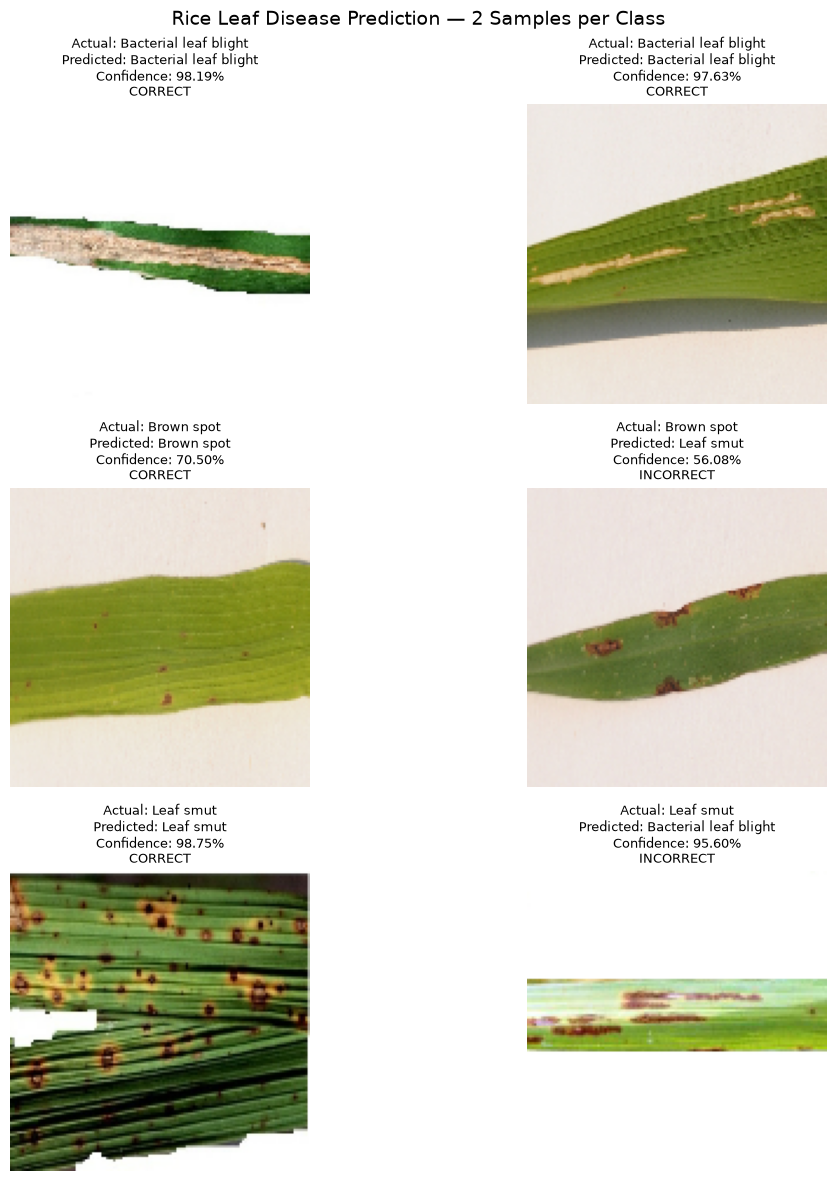

Bacterial leaf blight: 2 sample(s) displayed
Brown spot: 2 sample(s) displayed
Leaf smut: 2 sample(s) displayed


In [28]:

SAMPLES_PER_CLASS = 2

# Store up to 2 test images from each actual class
samples = {i: [] for i in range(len(class_names))}

for images, labels in test_ds:
    for image, label in zip(images, labels):
        actual_idx = int(label.numpy())

        if len(samples[actual_idx]) < SAMPLES_PER_CLASS:
            samples[actual_idx].append(image.numpy())

    if all(len(samples[i]) >= SAMPLES_PER_CLASS for i in samples):
        break

# Display sample predictions
fig, axes = plt.subplots(
    len(class_names),
    SAMPLES_PER_CLASS,
    figsize=(12, 12)
)

for class_idx, class_name in enumerate(class_names):
    for sample_idx in range(SAMPLES_PER_CLASS):
        ax = axes[class_idx, sample_idx]

        if sample_idx >= len(samples[class_idx]):
            ax.set_title("Sample not available")
            ax.axis("off")
            continue

        image_array = samples[class_idx][sample_idx]

        # Model accepts 128x128 RGB images.
        # cnn_aug includes its own Rescaling(1./255) layer.
        prediction = cnn_aug.predict(
            np.expand_dims(image_array, axis=0),
            verbose=0
        )

        predicted_idx = int(np.argmax(prediction[0]))
        predicted_class = class_names[predicted_idx]
        confidence = float(prediction[0][predicted_idx]) * 100

        ax.imshow(np.clip(image_array / 255.0, 0, 1))
        ax.axis("off")

        result = "CORRECT" if predicted_idx == class_idx else "INCORRECT"

        ax.set_title(
            f"Actual: {class_name}\n"
            f"Predicted: {predicted_class}\n"
            f"Confidence: {confidence:.2f}%\n"
            f"{result}",
            fontsize=9
        )

        print(f"Actual: {class_name}")
        print(f"Predicted: {predicted_class}")
        print(f"Confidence: {confidence:.2f}%")
        print("-" * 35)

plt.suptitle(
    "Rice Leaf Disease Prediction — 2 Samples per Class",
    fontsize=14
)
plt.tight_layout()
plt.show()

# Check sample availability
for i, name in enumerate(class_names):
    print(f"{name}: {len(samples[i])} sample(s) displayed")


## 14. Conclusion

This project developed a CNN-based model to classify rice leaf diseases into Bacterial Leaf Blight, Brown Spot, and Leaf Smut.  
The basic CNN achieved a test accuracy of **68.75%**, while CNN with data augmentation improved it to **71.88%**.  
Sample predictions showed that the model can correctly identify several rice leaf images with high confidence.  
However, some images were misclassified, indicating scope for further improvement.  
Model performance can be enhanced using more training images, better data preprocessing, and hyperparameter tuning.  
Overall, this project demonstrates the potential of deep learning for early rice leaf disease detection and supporting farmers in crop management.

## 15. Final Project Conclusion

This project builds a simple CNN-based rice leaf disease classifier for:

- **Leaf smut**
- **Brown spot**
- **Bacterial leaf blight**

The project first analyzes the dataset, then trains a basic CNN, evaluates it, applies data augmentation, compares the two approaches, and recommends the better-performing approach.

### Key learning points

1. Data analysis should come before model training.
2. Image resizing makes input dimensions consistent.
3. CNNs automatically learn visual features.
4. Data augmentation is useful when the dataset is small.
5. Accuracy alone is not enough; use precision, recall, F1-score and a confusion matrix.
6. A production model should be tested on realistic images before deployment.

